In [28]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table

def inspect_galaxy_result(results_dir="results",
                          summary_fits="statmorph_summary.fits",
                          galaxy_id=None,
                          show_errors=False):
    """
    Display morphological results and image for a given galaxy.

    Parameters
    ----------
    results_dir : str
        Path to the folder containing Sérsic model PNGs (e.g., "results").
    summary_fits : str
        Path to the FITS summary file (e.g., "statmorph_summary.fits").
    galaxy_id : int or None
        ID of the galaxy to inspect. If None, prompts user input.
    show_errors : bool, optional
        Whether to display error estimates (default=True).
    """
    # --- Load FITS table ---
    if not os.path.exists(summary_fits):
        raise FileNotFoundError(f"Could not find summary FITS: {summary_fits}")

    table = Table.read(summary_fits)

    # --- Get or request galaxy ID ---
    if galaxy_id is None:
        galaxy_id = input("Enter galaxy ID to inspect: ").strip()
    try:
        galaxy_id = float(galaxy_id)
    except ValueError:
        raise ValueError("Galaxy ID must be numeric.")

    # --- Find matching row ---
    matches = table[table['Id'] == galaxy_id]
    if len(matches) == 0:
        print(f"No entry found for galaxy ID {galaxy_id}.")
        return

    row = matches[0]

    # --- Build image path ---
    image_path = os.path.join(results_dir, f"sersic_morph_galaxy_{int(galaxy_id)}.png")
    if not os.path.exists(image_path):
        print(f"Image not found at: {image_path}")
        image_path = None

    # --- Display morphological info ---
    print("\n" + "="*70)
    print(f" GALAXY ID: {int(galaxy_id)} | SURVEY: {row['Survey']}")
    print("="*70)

    print("\nPhotometric & Structural Parameters:")
    print("------------------------------------")
    print(f"  mag         = {row['mag']:.3f}")
    print(f"  R_e [pix]   = {row['R_e']:.3f}")
    print(f"  n (Sérsic)  = {row['n']:.3f}")
    print(f"  q (b/a)     = {row['q']:.3f}")
    print(f"  P.A. [deg]  = {row['P.A.']:.2f}")
    print(f"  Chi²/ν      = {row['Chi^2/nu']:.3f}")

    # --- Optional error block ---
    if show_errors:
        print("\nEstimated Errors:")
        print("-----------------")
        error_keys = ['e_mag', 'e_Re', 'e_n', 'e_q', 'e_PA']
        for key in error_keys:
            if key in row.colnames:
                val = row[key]
                print(f"  {key:<6} = {val:.4f}" if np.isfinite(val) else f"  {key:<6} = n/a")
            else:
                print(f"  {key:<6} = n/a (not in table)")
        print("\n")

    # --- Show image ---
    if image_path:
        img = plt.imread(image_path)
        plt.figure(figsize=(12, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"Sérsic Morphology – Galaxy {int(galaxy_id)}")
        plt.show()
    else:
        print("(No corresponding image found.)")



 GALAXY ID: 58 | SURVEY: CEERS

Photometric & Structural Parameters:
------------------------------------
  mag         = 20.515
  R_e [pix]   = 13.326
  n (Sérsic)  = 1.217
  q (b/a)     = 0.568
  P.A. [deg]  = -74.29
  Chi²/ν      = 4.977


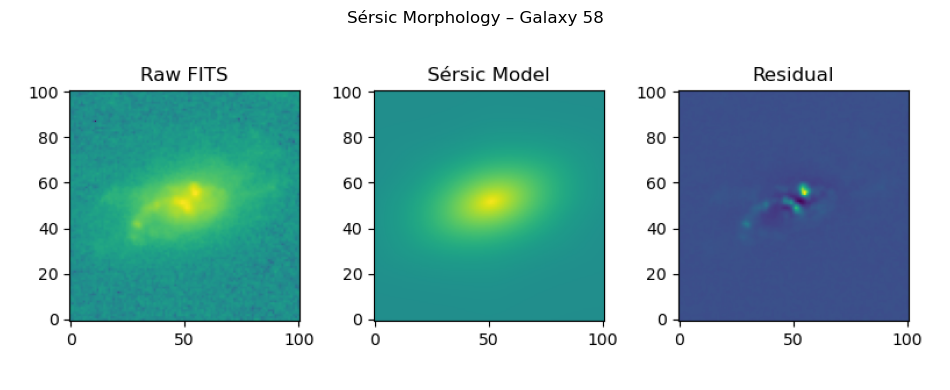

In [36]:
inspect_galaxy_result(
    results_dir="galaxy_cutouts/ceers/f115w/results",
    summary_fits="galaxy_cutouts/ceers/f115w/results/statmorph_summary.fits",
    galaxy_id=58  # or leave None to prompt interactively
)
